# Tracer populations in a simulation

This tutorial paints stellar tracer populations onto the dark matter halo of an isolated Milky Way
simulation (Gadget-4, $10^8$ dark matter particles, disc and bulge, radially anisotropic halo), follows
them through 5 time units (0.98 Gyr each), and writes mock catalogues.

It uses a random sample of $10^6$ halo particles, the same particles in every snapshot, made with
`tests/make_sim_sample.py`. The simulation is not public, so this notebook is shown as it was run. The
units are kpc, km/s, M$_\odot$ and (km/s)$^2$, as `stracers` expects (see the Units page).

In [1]:
import os
import tempfile
import warnings

import h5py
import numpy as np
import matplotlib.pyplot as plt

import stracers
from stracers.plotting import LATEX_STYLE

plt.rcParams.update(LATEX_STYLE)
SAMPLE = os.environ.get("STRACERS_SIM_SAMPLE", os.path.expanduser("~/.cache/stracers/mw_iso_b1_1M.hdf5"))

def load(snapshot):
    with h5py.File(SAMPLE, "r") as f:
        g = f[snapshot]
        return dict(pos=g["pos"][()].astype(float), vel=g["vel"][()].astype(float), pot=g["pot"][()].astype(float),
                    ids=g["ids"][()], t=float(g.attrs["time"]), mass=float(g.attrs["mass"]),
                    center=g.attrs["center"], vcenter=g.attrs["vcenter"])

snaps = {s: load(s) for s in ["000", "010", "044", "110", "250"]}
for s, d in snaps.items():
    print(f"snapshot {s}: t = {d['t']:.2f}, centre = {np.round(d['center'], 2)} kpc")

snapshot 000: t = 0.00, centre = [-0.34 -0.29  0.01] kpc
snapshot 010: t = 0.20, centre = [-0.25 -0.09  0.08] kpc
snapshot 044: t = 0.88, centre = [-0.37  0.21 -0.35] kpc
snapshot 110: t = 2.20, centre = [-0.19 -0.12  0.11] kpc
snapshot 250: t = 5.00, centre = [-0.36 -0.59 -0.47] kpc


## Painting the populations

`paint_tracer` chooses the most recent literature profile for each tracer that covers 20–100 kpc,
computes the weights of the whole stellar halo, and keeps the particles in the range. Passing `ids` lets us
follow the populations to other snapshots. We paint on the snapshot at $t = 2.2$, when the halo has
relaxed (see below).

In [2]:
s = snaps["110"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    pops = {t: stracers.paint_tracer(s["pos"], s["vel"], s["pot"], s["mass"], t, (20, 100), n_stars=3000,
                                     ids=s["ids"], center=s["center"], snapshot="110")
            for t in ["RRLyr", "BHB"]}
for t, pop in pops.items():
    print(f"{t}: {pop.reference} ({pop.key}), {pop.total:.0f} stars on {pop.in_range.sum()} particles")

RRLyr: Medina et al. 2024 (medina2024), 3000 stars on 395040 particles
BHB: Thomas et al. 2018 (thomas2018), 3000 stars on 395040 particles


## Following them in time

`at_snapshot` carries the stars of each particle by ID to another snapshot and selects the radial range
again around that snapshot's centre. The stars are conserved, not renormalised. In an isolated halo in
equilibrium, a population whose stars depend only on energy is a steady state, so the shell counts and
dispersions should not change:

RRLyr: 3000 stars in 20-100 kpc at t = 5.0 (3000 at t = 2.2), matched fraction 1.000
BHB: 3008 stars in 20-100 kpc at t = 5.0 (3000 at t = 2.2), matched fraction 1.000


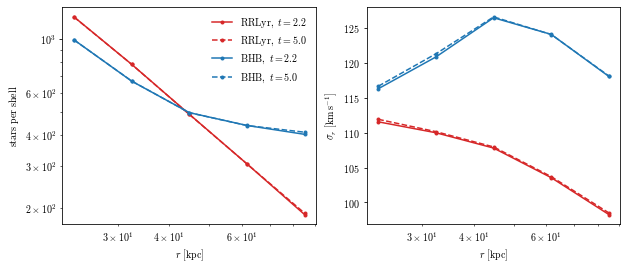

In [3]:
edges = np.geomspace(20, 100, 6)
rc = np.sqrt(edges[1:] * edges[:-1])
shells = lambda p: np.histogram(np.linalg.norm(p.pos, axis=1), edges, weights=p.n_stars)[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for (t, pop), color in zip(pops.items(), ["C3", "C0"]):
    for snap, ls in [("110", "-"), ("250", "--")]:
        d = snaps[snap]
        p = pop.at_snapshot(d["ids"], d["pos"], d["vel"], center=d["center"], snapshot=snap)
        prof = p.velocity_profile(bins=edges, vcenter=d["vcenter"])
        label = r"$\mathrm{" + t + r"},\ t = %.1f$" % d["t"]
        axes[0].plot(rc, shells(p), ls, color=color, marker="o", ms=3, label=label)
        axes[1].plot(prof.r, prof.sigma_r, ls, color=color, marker="o", ms=3)
        if snap == "250":
            print(f"{t}: {p.total:.0f} stars in 20-100 kpc at t = 5.0 (3000 at t = 2.2), "
                  f"matched fraction {p.matched_fraction:.3f}")
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel(r"$r\ [\mathrm{kpc}]$")
axes[0].set_yscale("log"); axes[0].set_ylabel(r"$\mathrm{stars\ per\ shell}$"); axes[0].legend(frameon=False)
axes[1].set_ylabel(r"$\sigma_r\ [\mathrm{km\,s^{-1}}]$");

## Stars beyond rmax, and the initial conditions

Two things matter for a stationary population:

- **Stars beyond rmax.** The weights are computed from the particles inside `rmax` (300 kpc by default),
  but `paint_tracer` gives stars to *every* particle according to its energy (`beyond_rmax="energy"`).
  Otherwise, stars on orbits reaching beyond `rmax` would be missing, and the population would drift
  outwards. This matters for the shallow BHB profile.
- **The initial conditions** of the simulation relax during the first ~1 Gyr, so a population painted on
  them settles with the halo, a few per cent lower, before becoming stationary.

The number of stars in 20–100 kpc against time:

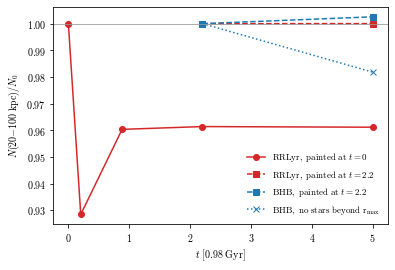

In [4]:
def count_vs_time(snapshot, tracer, **kw):
    s = snaps[snapshot]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        pop = stracers.paint_tracer(s["pos"], s["vel"], s["pot"], s["mass"], tracer, (20, 100), n_stars=3000,
                                    ids=s["ids"], center=s["center"], **kw)
    later = [k for k in snaps if snaps[k]["t"] >= s["t"]]
    return ([snaps[k]["t"] for k in later],
            [pop.at_snapshot(snaps[k]["ids"], snaps[k]["pos"], snaps[k]["vel"], center=snaps[k]["center"]).total
             for k in later])

fig, ax = plt.subplots(figsize=(6, 4))
for args, kw, style, label in [
        (("000", "RRLyr"), {}, "C3o-", r"$\mathrm{RRLyr,\ painted\ at}\ t = 0$"),
        (("110", "RRLyr"), {}, "C3s--", r"$\mathrm{RRLyr,\ painted\ at}\ t = 2.2$"),
        (("110", "BHB"), {}, "C0s--", r"$\mathrm{BHB,\ painted\ at}\ t = 2.2$"),
        (("110", "BHB"), {"beyond_rmax": "zero"}, "C0x:", r"$\mathrm{BHB,\ no\ stars\ beyond\ r_{max}}$")]:
    t, n = count_vs_time(*args, **kw)
    ax.plot(t, np.array(n) / 3000, style, label=label)
ax.axhline(1, color="0.6", lw=0.8)
ax.set_xlabel(r"$t\ [0.98\ \mathrm{Gyr}]$")
ax.set_ylabel(r"$N(20{-}100\ \mathrm{kpc}) / N_0$")
ax.legend(frameon=False, fontsize=9);

## Saving a population

Paint once, save, and observe each snapshot later, e.g. in separate jobs, without computing the weights
again:

In [5]:
folder = tempfile.mkdtemp()
pops["RRLyr"].save(os.path.join(folder, "rrl_110.h5"))
loaded = stracers.load_population(os.path.join(folder, "rrl_110.h5"))
d = snaps["250"]
rrl_250 = loaded.at_snapshot(d["ids"], d["pos"], d["vel"], center=d["center"], snapshot="250")
print(f"{loaded.reference}, painted on snapshot {loaded.snapshot}: {rrl_250.total:.0f} stars in range at t = {d['t']}")

Medina et al. 2024, painted on snapshot 110: 3000 stars in range at t = 5.0


## Mock catalogues

`write_catalogue` writes a mock catalogue: one row per star (a Poisson draw), or one row per particle with
its expected number of stars. It writes in chunks, so catalogues of $10^8$ stars fit in a couple of GB of
memory. Here, an RR Lyrae catalogue at $t = 5$, in HDF5 and CSV:

In [6]:
n = stracers.write_catalogue(rrl_250, os.path.join(folder, "rrl_250.h5"), rng=0, vcenter=d["vcenter"])
stracers.write_catalogue(rrl_250, os.path.join(folder, "rrl_250_particles.csv"), kind="particles",
                         columns=["id", "r", "v_r", "v_theta", "v_phi", "n_stars"], vcenter=d["vcenter"])
cols, meta = stracers.read_catalogue(os.path.join(folder, "rrl_250.h5"))
print(f"{n} mock stars; columns: {list(cols)}")
print({k: meta[k] for k in ["tracer", "key", "kind", "n_rows", "seed", "snapshot", "r_range"]})
print("sigma of v_r in the catalogue: %.1f km/s" % np.std(cols["v_r"]))

2969 mock stars; columns: ['id', 'x', 'y', 'z', 'vx', 'vy', 'vz', 'r', 'v_r', 'v_theta', 'v_phi']
{'tracer': 'RR Lyrae', 'key': 'medina2024', 'kind': 'stars', 'n_rows': 2969, 'seed': 0, 'snapshot': '250', 'r_range': [20.0, 100.0]}
sigma of v_r in the catalogue: 110.4 km/s
